# 29 — The Rules, and the Price of Every Number in This Project

Twenty-eight notebooks produced results. Several of them produced something more
portable: a **rule about what a number has to survive before it counts**. Each
rule was paid for by a specific measurement, usually an uncomfortable one, and
each is currently stated inside the notebook that found it. This notebook states
them once, and then applies them to this project's own numbers.

That second half is the point. Paper A argues that a reported accuracy or error
in this field is not evidence until it has been priced against something — a
permuted-label null, a degenerate baseline, or chance. A paper making that
argument has to submit its own claims to it, so every number the paper will
quote is collected in one table, `results/registry.csv`, with its comparator
beside it.

The registry is built by `src/build_registry.py`. All thirty-one of its rows are
**recomputed from the cached result files**, so none of them can drift from the
notebook that produced it. Six used to be quoted from notebooks whose
intermediates were never cached; those notebooks now write their intermediates
to CSV, and no number in the table is typed in by hand.

In [1]:
import pathlib

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

OUT = pathlib.Path("../data/processed")
R = pd.read_csv("../results/registry.csv")

C_BLUE, C_ORANGE = "#2a78d6", "#eb6834"
INK, INK2, MUTED = "#0b0b0b", "#52514e", "#898781"
GRID, BASE, SURFACE = "#e1e0d9", "#c3c2b7", "#fcfcfb"
plt.rcParams.update({
    "font.family": "sans-serif", "font.sans-serif": ["Segoe UI", "DejaVu Sans"],
    "text.color": INK, "axes.titlecolor": INK, "axes.labelcolor": INK2,
    "xtick.color": MUTED, "ytick.color": MUTED, "axes.edgecolor": BASE,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.8,
    "axes.spines.top": False, "axes.spines.right": False,
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "legend.frameon": False,
})

print(f"{len(R)} claims · {int((R.source == 'recomputed').sum())} recomputed from cache · "
      f"{int((R.source != 'recomputed').sum())} quoted from a notebook")
print(R.verdict.replace("", "no null applicable").value_counts().to_string())
print()
print(R[["notebook", "rig", "n_units", "claim", "value", "comparator_value", "p", "verdict"]]
      .to_string(index=False, max_colwidth=60))

# Phase 3.1: journal-resolution export of the manuscript figures (paper/figures/).
FIGDIR = pathlib.Path("../paper/figures")
FIGDIR.mkdir(parents=True, exist_ok=True)


def save(fig, name):
    """Vector PDF, a 600-dpi RGB TIFF, and a greyscale proof for the print check.

    The TIFF is flattened onto white: an alpha channel leaves the background to
    whoever converts the file, and transparent can come back black.
    """
    from PIL import Image
    fig.savefig(FIGDIR / f"{name}.pdf", bbox_inches="tight")
    fig.savefig(FIGDIR / f"{name}.tif", dpi=600, bbox_inches="tight",
                pil_kwargs={"compression": "tiff_lzw"})
    im = Image.open(FIGDIR / f"{name}.tif")
    if im.mode in ("RGBA", "LA", "P"):
        im = im.convert("RGBA")
        flat = Image.new("RGB", im.size, "white")
        flat.paste(im, mask=im.split()[-1])
        im = flat
    im.save(FIGDIR / f"{name}.tif", compression="tiff_lzw", dpi=(600, 600))
    proof = im.convert("L")
    proof.thumbnail((1600, 1600))
    (FIGDIR / "greyscale-proofs").mkdir(exist_ok=True)
    proof.save(FIGDIR / "greyscale-proofs" / f"{name}.png")
    print(f"  saved {name}: vector pdf, {im.size[0]}x{im.size[1]} RGB tif at 600 dpi, "
          f"greyscale proof")


31 claims · 31 recomputed from cache · 0 quoted from a notebook
verdict
inside its null    6
clears its null    5

notebook       rig  n_units                                                        claim                              value comparator_value      p         verdict
 nb11/22 Paderborn       11                          race attribution, geometry features                             0.8545           0.6955 0.0043 clears its null
 nb21/22 Paderborn       11                         race attribution, load-zone features                             0.6273           0.7136 0.1472 inside its null
 nb14/22   XJTU-SY       11                          race attribution, geometry features                             0.9412           0.7188 0.0061 clears its null
 nb20/22   XJTU-SY       11                         race attribution, load-zone features                             0.8971           0.7387 0.0061 clears its null
 nb18/24   XJTU-SY       11                      race attribution

## The ruler

All eleven of the project's attribution numbers were scored against their own permuted-label null — the same protocol, the same units, the labels reassigned every way that preserves the class counts. The null's 95th percentile is what the number had to beat. `LZ_frdev` is included as the cautionary case: a pure shaft-speed reading, incapable of diagnosing anything, which clears the band. It has no null of its own, so it is drawn against the XJTU-SY geometry null on the same units.

  saved fig1_attribution_vs_null: vector pdf, 6779x3353 RGB tif at 600 dpi, greyscale proof


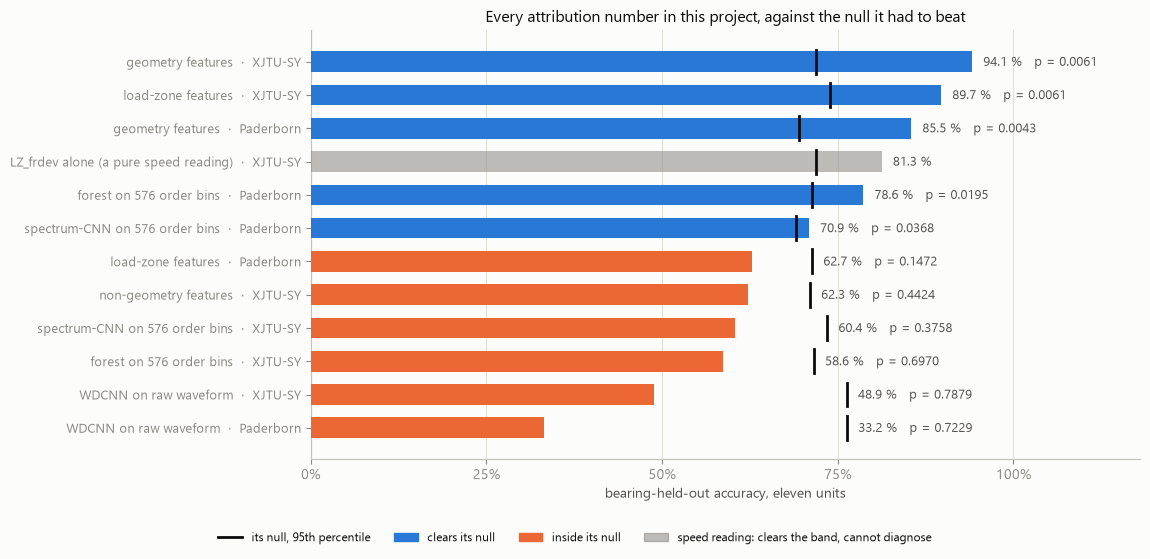

null 95th percentiles span 0.691 to 0.764 across models and rigs
clears: ['spectrum-CNN on 576 order bins  ·  Paderborn', 'forest on 576 order bins  ·  Paderborn', 'geometry features  ·  Paderborn', 'load-zone features  ·  XJTU-SY', 'geometry features  ·  XJTU-SY']
inside: ['WDCNN on raw waveform  ·  Paderborn', 'WDCNN on raw waveform  ·  XJTU-SY', 'forest on 576 order bins  ·  XJTU-SY', 'spectrum-CNN on 576 order bins  ·  XJTU-SY', 'non-geometry features  ·  XJTU-SY', 'load-zone features  ·  Paderborn']


In [2]:
acc = R[R.claim.str.startswith("race attribution") & R.comparator.str.contains("null", na=False)].copy()
acc["label"] = acc.claim.str.replace("race attribution, ", "", regex=False) + "  ·  " + acc.rig
acc = acc.sort_values("value")
fig, ax = plt.subplots(figsize=(11.6, 5.6))
y = np.arange(len(acc))
for yi, (_, r) in zip(y, acc.iterrows()):
    # a row with no p of its own is a control, not a test: LZ_frdev, drawn against the
    # geometry null on the same units. It clears that null and still diagnoses nothing.
    control = pd.isna(r.p)
    col = MUTED if control else (C_BLUE if r.verdict == "clears its null" else C_ORANGE)
    v = float(str(r.value).rstrip(" %")) / (100 if "%" in str(r.value) else 1)
    nv = float(str(r.comparator_value).rstrip(" %")) / (100 if "%" in str(r.comparator_value) else 1)
    ax.barh(yi, 100 * v, height=0.62, color=col, zorder=3, alpha=0.55 if control else 1.0)
    ax.plot([100 * nv] * 2, [yi - 0.36, yi + 0.36], color=INK, lw=2.0, zorder=5)
    # anchor right of whichever is further out, or the null marker strikes through the text
    ax.annotate(f"{100 * v:.1f} %" + ("" if pd.isna(r.p) else f"   p = {r.p:.4f}"),
                (max(100 * v, 100 * nv), yi),
                xytext=(8, -3), textcoords="offset points", fontsize=9, color=INK2)
from matplotlib.patches import Patch
from matplotlib.lines import Line2D
handles = [Line2D([], [], color=INK, lw=2.0, label="its null, 95th percentile"),
           Patch(color=C_BLUE, label="clears its null"),
           Patch(color=C_ORANGE, label="inside its null"),
           Patch(color=MUTED, alpha=0.55, label="speed reading: clears the band, cannot diagnose")]
ax.set_yticks(y, acc.label, fontsize=9)
ax.set_xlim(0, 118)
ax.set_xticks([0, 25, 50, 75, 100], ["0%", "25%", "50%", "75%", "100%"])
ax.grid(axis="y", visible=False)
ax.set_xlabel("bearing-held-out accuracy, eleven units")
fig.legend(handles=handles, fontsize=8.5, loc="lower center", ncol=4, bbox_to_anchor=(0.5, 0.0), frameon=False)
ax.set_title("Every attribution number in this project, against the null it had to beat", fontsize=11.5)
plt.tight_layout(rect=(0, 0.07, 1, 1))
save(fig, "fig1_attribution_vs_null")
plt.show()

band = acc[acc.p.notna()].comparator_value.astype(float)
print(f"null 95th percentiles span {band.min():.3f} to {band.max():.3f} across models and rigs")
print("clears:", acc[acc.verdict == "clears its null"].label.tolist())
print("inside:", acc[acc.verdict == "inside its null"].label.tolist())

**The band runs from 69.1 % to 76.4 %, and it moves with the model and its input.** On eleven units the null's 95th percentile is 69.6–73.9 % for the forests (the hand-built feature sets and the forest on 576 order bins), 76.3–76.4 % for WDCNN on the raw waveform, and 69.1–73.5 % for the small spectrum-CNN — so the highest and the lowest thresholds in the project both belong to networks, and a number anywhere in that range says nothing until its *own* null has been run. Six of the project's eleven attribution numbers sit inside their own null: the load-zone channel on Paderborn, the non-geometry channel on XJTU-SY, both spectrum models on XJTU-SY, and WDCNN on both rigs. Every one of the eleven is now priced against a complete enumeration — 165 labellings on XJTU-SY, 462 on Paderborn — with no sampled *p* left in the table.

Two rows make the case that the null is necessary but not sufficient. `LZ_frdev` — a feature that reads shaft speed and nothing else — scores **81.3 %** and clears the band. The decoy fold at 1.37 × shaft rate, built to be incapable, scores 44.1 % against the true fold's 65.5 %. A permutation null answers *"is the class structure real?"*; a deliberately incapable control answers *"can this feature carry what its name suggests?"* Those are different questions, and this project needs both because each has caught something the other missed.

## How many units a claim needs

The band narrows as units are added, so the same measurement asks a second question: at what study size does a *real* effect become detectable? Subsets of *n* bearings were scored under the true labels and against a null permuted inside that same subset, so the band reflects the size being tested. The channels each rig's exact null found to be absent are the negative controls.

  saved fig2_study_size_curves: vector pdf, 7493x2793 RGB tif at 600 dpi, greyscale proof


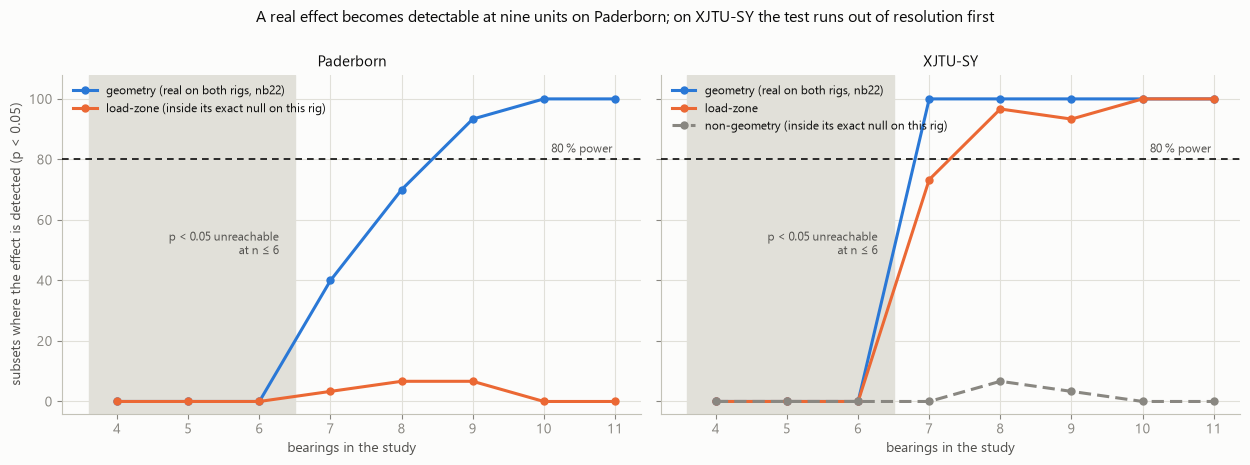

      rig value                                                                                                                                                                                                     note
Paderborn     9 28 of 30 subsets at n=9, 93% (Clopper-Pearson 95 % CI [78%, 99%], and the subsets share units so it is optimistic); rate by unit count n=4: 0%, n=5: 0%, n=6: 0%, n=7: 40%, n=8: 70%, n=9: 93%, n=10:...
  XJTU-SY     7 30 of 30 subsets at n=7, 100% (Clopper-Pearson 95 % CI [88%, 100%], and the subsets share units so it is optimistic); rate by unit count n=4: 0%, n=5: 0%, n=6: 0%, n=7: 100%, n=8: 100%, n=9: 100%, ...


In [3]:
fig, axes = plt.subplots(1, 2, figsize=(12.6, 4.6), sharey=True)
STY = {"geometry": (C_BLUE, "-", "geometry (real on both rigs, nb22)"),
       "load-zone": (C_ORANGE, "-", "load-zone"), "non-geometry": (MUTED, (0, (4, 2)), "non-geometry")}
for ax, (rig, f) in zip(axes, (("Paderborn", "power_curve.csv"), ("XJTU-SY", "power_curve_xjtu.csv"))):
    pc = pd.read_csv(OUT / f)
    for ch, g in pc.groupby("channel"):
        col, ls, lab = STY[ch]
        det = g.groupby("n").apply(lambda d: (d.p < 0.05).mean(), include_groups=False)
        if ch != "geometry":
            lab = f"{ch} (inside its exact null on this rig)" if (rig, ch) in (("Paderborn", "load-zone"), ("XJTU-SY", "non-geometry")) else ch
        ax.plot(det.index, 100 * det.values, color=col, ls=ls, lw=2.2, marker="o", ms=5, zorder=3, label=lab)
    # Below the unit count where the per-subset floor 1/(N+1) drops under 0.05, no subset
    # can reach significance however large the effect is. Zero detections there are a
    # property of the design, so the region is marked rather than left to be misread.
    floor = 1 / (pc.groupby("n")["n_perm"].median() + 1)
    blind = [int(k) for k, v in floor.items() if v > 0.05]
    if blind:
        ax.axvspan(pc.n.min() - 0.4, max(blind) + 0.5, color=GRID, zorder=1)
        ax.annotate(f"p < 0.05 unreachable\nat n \u2264 {max(blind)}", (max(blind) + 0.35, 52),
                    xytext=(-4, 0), textcoords="offset points", fontsize=8.5, color=INK2,
                    ha="right", va="center")
    ax.axhline(80, color=INK, lw=1.2, ls=(0, (4, 3)), zorder=4)
    ax.annotate("80 % power", (pc.n.max(), 80), xytext=(-2, 5), textcoords="offset points",
                fontsize=8.5, color=INK2, ha="right")
    ax.set_xlabel("bearings in the study")
    ax.set_ylim(-4, 108)
    ax.set_title(rig, fontsize=10.5)
    ax.legend(fontsize=8.5, loc="upper left")
axes[0].set_ylabel("subsets where the effect is detected (p < 0.05)")
fig.suptitle("A real effect becomes detectable at nine units on Paderborn; on XJTU-SY the test runs out of resolution first", fontsize=11.5, y=1.0)
plt.tight_layout()
save(fig, "fig2_study_size_curves")
plt.show()

print(R[R.claim.str.startswith("units needed")][["rig", "value", "note"]].to_string(index=False, max_colwidth=200))

**Nine units on Paderborn, seven on XJTU-SY, and eleven is not comfortable.** The rig with the larger effect needs fewer, as it should. On Paderborn the real effect is detected in **no subset at n = 4–6**, 5 of 12 at n = 7 and 4 of 12 at n = 8; at **n = 9** the margin over the null jumps to **+17.7 points** and 11 of 12 subsets reach p < 0.05, with 9 of 11 at n = 10. On XJTU-SY detection is 10 of 12 at n = 7 and complete from n = 8. Both curves are non-monotonic in the middle because subsets at a given size reuse the same bearings and are far from independent — which is itself a limit on how precisely these thresholds can be read. (The measurement-log entry for notebooks 23–24 quoted different counts for Paderborn; they match neither the cached curve nor notebook 24's own output, and were corrected on 2026-09-20. The thresholds and the negative controls are unaffected.)

The negative controls behave: the channels that sit inside their exact null are detected in almost no subset at any size. The curve finds the real effect and not the absent one.

Two cautions belong with these numbers. The power comes as much from the **null narrowing** as from accuracy rising, which a plain learning curve cannot show — so "how many units before an effect is *detectable*" is a different and harder question than "how many units before accuracy *saturates*", which notebook 14 answered at about six. And this threshold is itself measured on eleven units.

## The five rules

Each rule is a way a number in this project was nearly reported wrongly, and the notebook that caught it.

| # | Rule | What it caught |
|---|---|---|
| 1 | **Report a permuted-label null *and* a deliberately incapable control. Both, always.** | `LZ_frdev`, a pure speed reading, scored 81.3 % and cleared the null — the control caught it. The Paderborn load-zone channel cleared the control and sat inside the null — the null caught it. Neither test subsumes the other (nb20, nb21, nb22). |
| 2 | **A null belongs to a model. Never borrow another model's band.** | WDCNN's null runs 4–7 points wider than the forest's on the same labellings (76.3/76.4 % against 71.9/69.5 %), because a higher-capacity model finds more ways to fit an arbitrary grouping of eleven units (nb28). |
| 3 | **Put a degenerate baseline beside any error in minutes.** | Predicting *zero life left* beats every remaining-life estimator in the project after the alarm (51 min against 57, 78 and 89), and is 7.1× better than the model in the last fifth of life. An MAE on this benchmark can be won without reading a sensor (nb27). |
| 4 | **Report a learned model's fingerprint rate beside its accuracy.** | The network that cannot name the race identifies individual bearings at 99.5 % and 95.8 %. With eleven units, identity is a usable proxy for class, and the accuracy alone does not reveal that it was used (nb21, nb28). |
| 5 | **Report calibration with discrimination and resolution. Never alone.** | Replacing the phase key with noise *improved* calibration error by 0.002 while discrimination fell 24 points. Calibration cannot detect a dead key (nb25). |

Two further requirements are not rules about a statistic but about how a result is read:

* **A per-unit promise cannot be underwritten by a population statistic.** The floor is "91 % safe" as a median over bearings of which *none* is 90 % safe in every fleet, and two are never safe in any. The same shape appeared in per-unit calibration (nb08, nb13) and in the reliability layer, whose honest between-unit interval was [0 %, 100 %] (nb25, nb26).
* **Report the bearings-versus-snapshots split for anything pooled over units.** On XJTU-SY three bearings supply 71 % of the snapshots; floor safety correlates +0.05 with bearing count and −0.21 with snapshot count, so "more data" can mean the opposite of what it seems (nb26).

And one reproducibility note, which cost a day to find: **CPU PyTorch is not bit-stable across thread counts.** The Paderborn true labelling moved 35.9 % → 33.2 % between 3 and 5 threads. Every number compared against a null in notebook 28 was re-run at one thread count, and everything scored twice agrees exactly (nb28).

### Findings

1. **The project's own numbers are now priced in one table.** `results/registry.csv` holds 31 claims with their comparators, every one recomputed from cached results. Five claims clear their null, six sit inside it, and the rest are measured against a degenerate baseline or chance.
2. **The null band on eleven units runs 69.1–76.4 %, and it belongs to the model and its input.** 69.6–73.9 % for the forests (the hand-built feature sets and the forest on order bins), 76.3–76.4 % for WDCNN on the raw waveform, 69.1–73.5 % for the small spectrum-CNN — so the highest and the lowest thresholds both belong to networks, and on one rig's identical labellings they sit 7.3 points apart. Any bearing-held-out attribution number in that range is uninterpretable without its own null.
3. **A real effect needs nine units on Paderborn and seven on XJTU-SY**, so the eleven every attribution result here uses is marginal rather than comfortable. The negative controls are detected in almost no subset at any size, so the curve measures what it claims to.
4. **Five rules, each earned by a result**: null *and* incapable control together; one null per model; a degenerate baseline beside any error in minutes; a fingerprint rate beside any learned accuracy; calibration never reported alone. Plus two reading requirements — a per-unit promise is not a population statistic, and anything pooled over units reports the bearings-versus-snapshots split.
5. **No claim rests on an uncached intermediate any more.** The six that used to be quoted (nb13, nb17, nb25 ×2, nb20, nb21) are recomputed from the CSVs those notebooks now write, so every row in the registry reproduces from cache.